In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/evaluation_results.csv")
df["day"] = pd.to_datetime(df["day"])

print(df.shape)
print(df.head())

(330452, 11)
      user        day  login_count  logout_count  after_hours_count  \
0  AAE0190 2010-01-04            1             1                  1   
1  AAE0190 2010-01-05            1             1                  1   
2  AAE0190 2010-01-06            1             1                  1   
3  AAE0190 2010-01-07            1             1                  1   
4  AAE0190 2010-01-08            1             1                  1   

   weekend_count  unique_pcs  total_events  anomaly_score  anomaly  actual  
0              0           1             2       0.271602        0       0  
1              0           1             2       0.271602        0       0  
2              0           1             2       0.271602        0       0  
3              0           1             2       0.271602        0       0  
4              0           1             2       0.271602        0       0  


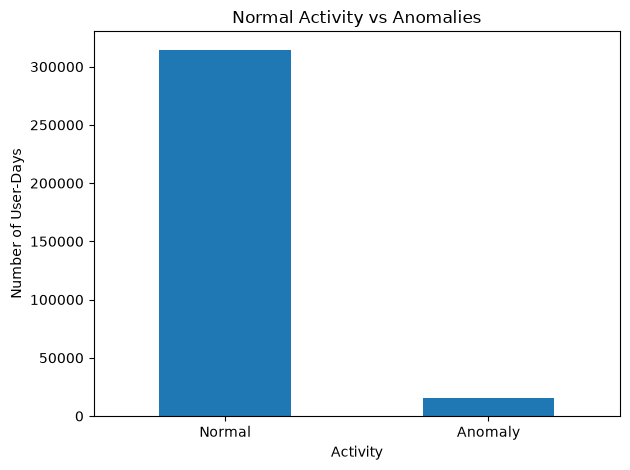

In [3]:
counts = df["anomaly"].value_counts().rename({
    0: "Normal",
    1: "Anomaly"
})

counts.plot(kind="bar", rot=0)
plt.title("Normal Activity vs Anomalies")
plt.xlabel("Activity")
plt.ylabel("Number of User-Days")
plt.tight_layout()
plt.show()

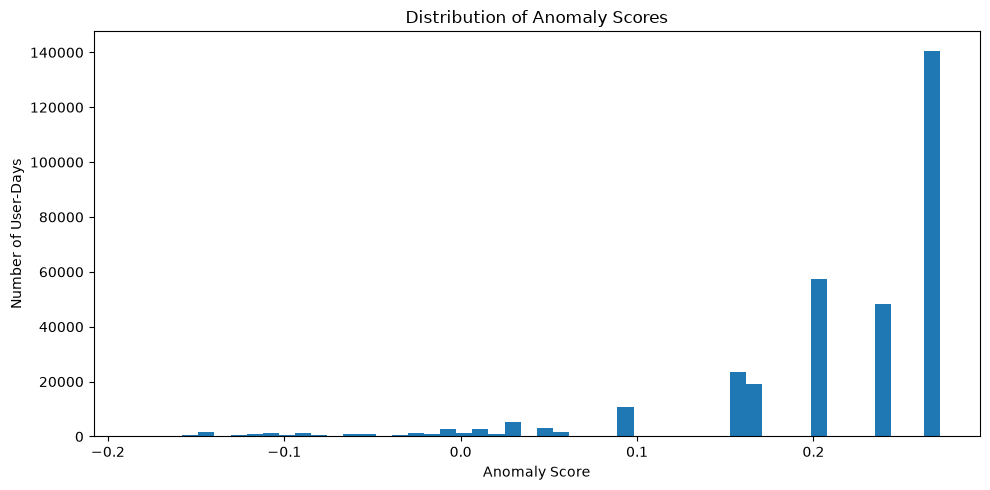

In [4]:
plt.figure(figsize=(10, 5))

plt.hist(df["anomaly_score"], bins=50)

plt.title("Distribution of Anomaly Scores")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of User-Days")
plt.tight_layout()
plt.show()

In [5]:
top_anomalies = df[df["anomaly"] == 1].nsmallest(
    20, "anomaly_score"
)

top_anomalies[
    [
        "user",
        "day",
        "login_count",
        "logout_count",
        "after_hours_count",
        "unique_pcs",
        "anomaly_score"
    ]
]    

,user,day,login_count,logout_count,after_hours_count,unique_pcs,anomaly_score
11118,AJF0370,2010-03-13,7,6,5,6,-0.185237
44103,BSS0369,2010-03-27,7,7,4,7,-0.184680
44066,BSS0369,2010-02-14,7,7,6,7,-0.183567
320539,WPR0368,2011-05-07,6,6,2,6,-0.180236
44096,BSS0369,2010-03-20,6,6,4,6,-0.179682
44140,BSS0369,2010-05-09,6,6,4,6,-0.179682
44229,BSS0369,2010-08-22,6,6,4,6,-0.179682
320145,WPR0368,2010-01-30,6,6,4,6,-0.179682
320151,WPR0368,2010-02-07,6,6,4,6,-0.179682
320280,WPR0368,2010-07-11,6,6,4,6,-0.179682


In [6]:
comparison = pd.crosstab(
    df["actual"],
    df["anomaly"],
    rownames=["Actual"],
    colnames=["Predicted"]
)

print(comparison)

Predicted       0      1
Actual                  
0          313363  15725
1            1268     96


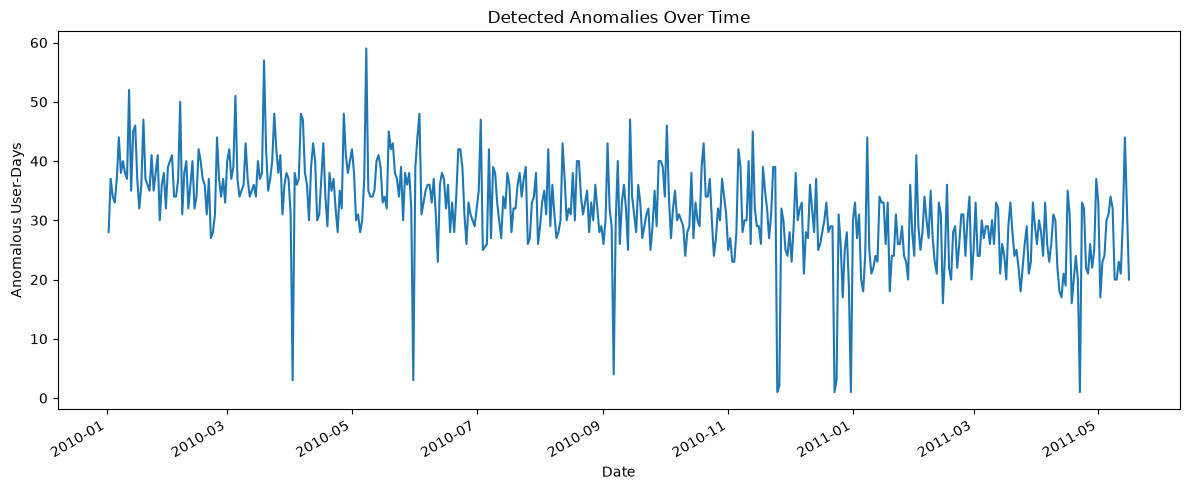

In [7]:
daily_anomalies = (
    df[df["anomaly"] == 1]
    .groupby("day")
    .size()
)

daily_anomalies.plot(figsize=(12, 5))

plt.title("Detected Anomalies Over Time")
plt.xlabel("Date")
plt.ylabel("Anomalous User-Days")
plt.tight_layout()
plt.show()

In [8]:
top_anomalies.to_csv(
    "../data/processed/top_anomalies.csv",
    index=False
)

print("Saved top_anomalies.csv")

Saved top_anomalies.csv


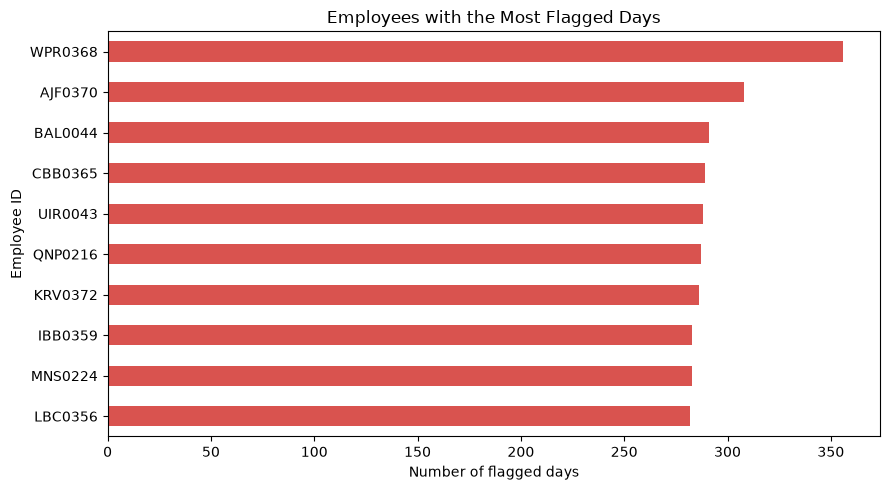

In [16]:
top_users = (
    df[df["anomaly"] == 1]
    .groupby("user")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(9, 5))
top_users.plot(kind="barh", color="#D9534F")

plt.title("Employees with the Most Flagged Days")
plt.xlabel("Number of flagged days")
plt.ylabel("Employee ID")
plt.tight_layout()
plt.show()

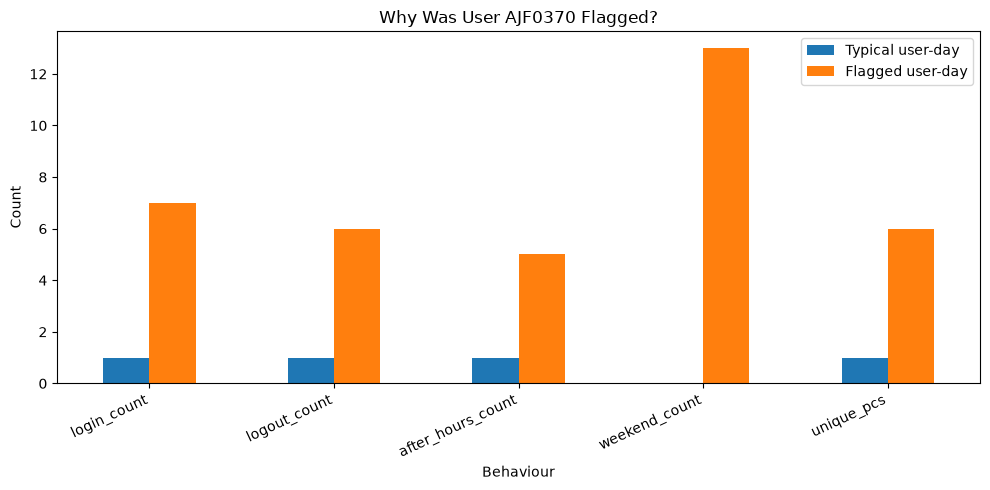

In [17]:
features = [
    "login_count",
    "logout_count",
    "after_hours_count",
    "weekend_count",
    "unique_pcs"
]

# Compare each flagged row against the dataset's median
typical = df[features].median()
flagged_rows = df[df["anomaly"] == 1]

if not flagged_rows.empty:
    example = flagged_rows.nsmallest(1, "anomaly_score").iloc[0]

    comparison = pd.DataFrame({
        "Typical user-day": typical,
        "Flagged user-day": example[features]
    })

    comparison.plot(kind="bar", figsize=(10, 5))
    plt.title(f"Why Was User {example['user']} Flagged?")
    plt.ylabel("Count")
    plt.xlabel("Behaviour")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()